# Challenge 1: Predict Apartment Rent
CAI 4105, Intro to Machine Learning

Pipeline: load data → preprocess → validate → compare models → tune → pick → predict.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import KFold, cross_validate
from sklearn.dummy import DummyRegressor

RANDOM_STATE = 42

## Step 1: Look at the data and prepare it
### 1.1 Load

In [13]:
train = pd.read_csv("Data/challenge1_train.csv")
test = pd.read_csv("Data/challenge1_test.csv")  # used ONLY in Step 6

print("train:", train.shape, " test:", test.shape)
train.head()

train: (7398, 10)  test: (2467, 9)


,ID,price,bathrooms,bedrooms,square_feet,latitude,longitude,category,has_photo,state
0,2,925,1.0,0,116,47.6160,-122.3275,housing/rent/apartment,Thumbnail,WA
1,3,2475,1.0,0,130,40.7629,-73.9885,housing/rent/apartment,Thumbnail,NY
2,5,1695,1.0,0,190,37.7599,-122.4379,housing/rent/apartment,Thumbnail,CA
3,6,1560,1.0,1,200,35.0847,-77.0609,housing/rent/apartment,Thumbnail,NC
4,7,1560,1.0,1,200,35.0960,-77.0272,housing/rent/apartment,Thumbnail,NC


### 1.2 Explore (EDA)

In [14]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7398 entries, 0 to 7397
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ID           7398 non-null   int64  
 1   price        7398 non-null   int64  
 2   bathrooms    7398 non-null   float64
 3   bedrooms     7398 non-null   int64  
 4   square_feet  7398 non-null   int64  
 5   latitude     7398 non-null   float64
 6   longitude    7398 non-null   float64
 7   category     7398 non-null   object 
 8   has_photo    7398 non-null   object 
 9   state        7398 non-null   object 
dtypes: float64(3), int64(4), object(3)
memory usage: 578.1+ KB


In [15]:
train.isna().sum()

,0
ID,0
price,0
bathrooms,0
bedrooms,0
square_feet,0
latitude,0
longitude,0
category,0
has_photo,0
state,0


In [16]:
train.describe().round(1)

,ID,price,bathrooms,bedrooms,square_feet,latitude,longitude
count,7398.0,7398.0,7398.0,7398.0,7398.0,7398.0,7398.0
mean,4954.1,1462.8,1.4,1.7,940.9,37.6,-94.4
std,2845.3,821.6,0.6,0.9,502.2,5.5,15.7
min,2.0,200.0,1.0,0.0,116.0,21.3,-158.0
25%,2495.2,949.0,1.0,1.0,650.0,33.6,-98.5
50%,4972.5,1273.5,1.0,2.0,807.5,38.8,-93.7
75%,7435.8,1695.0,2.0,2.0,1100.0,41.3,-81.6
max,9863.0,8800.0,7.0,9.0,5921.0,61.6,-70.3


In [17]:
for col in train.select_dtypes("object").columns:
    print(f"--- {col} ({train[col].nunique()} unique)")
    print(train[col].value_counts().head(10), "\n")

--- category (3 unique)
category
housing/rent/apartment     7395
housing/rent/home             2
housing/rent/short_term       1
Name: count, dtype: int64 

--- has_photo (3 unique)
has_photo
Thumbnail    6566
Yes           693
No            139
Name: count, dtype: int64 

--- state (50 unique)
state
TX    1327
CA     688
WA     375
MD     341
NC     340
NJ     294
GA     271
FL     249
OH     232
CO     230
Name: count, dtype: int64 



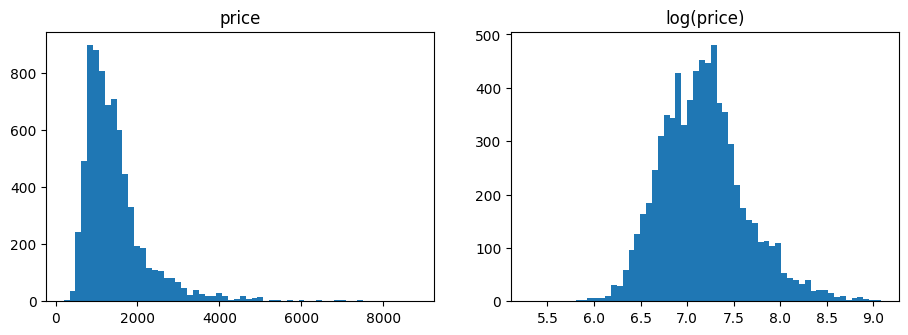

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(train["price"], bins=60)
axes[0].set_title("price")
axes[1].hist(np.log(train["price"]), bins=60)
axes[1].set_title("log(price)")
plt.show()

**What we found**
- 7,398 rows, no missing values (imputers stay in the pipeline as a safety net in case test has blanks).
- `price` is right-skewed ($200 to $8,800, median ≈ $1,274). `log(price)` looks much more symmetric, so it's worth trying in Step 4.
- `category` is almost always `housing/rent/apartment` (only 3 other rows), so it carries almost no information. We keep it; one-hot handles it.
- `ID` is just a row number and is **not** used as a feature.

### 1.3 Features and target

In [19]:
TARGET = "price"
NUM_COLS = ["bathrooms", "bedrooms", "square_feet", "latitude", "longitude"]
CAT_COLS = ["category", "has_photo", "state"]

X = train[NUM_COLS + CAT_COLS]
y = train[TARGET]
X.shape, y.shape

((7398, 8), (7398,))

### 1.4 Preprocessing (ColumnTransformer)
Numbers: median imputer (+ StandardScaler for linear models). Words: most-frequent imputer + one-hot. Trees don't need scaling, so `scale` is a switch.

In [20]:
def make_preprocessor(scale=False):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    cat_steps = [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
    return ColumnTransformer([
        ("num", Pipeline(num_steps), NUM_COLS),
        ("cat", Pipeline(cat_steps), CAT_COLS),
    ])

make_preprocessor(scale=True).fit_transform(X).shape

(7398, 61)

## Step 2: Validation strategy
5-fold cross-validation on the training file only, same folds and same metric (RMSE) for every model. Preprocessing lives inside the Pipeline, so it is re-fit on each training fold (no leakage).

In [21]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = "neg_root_mean_squared_error"

results = []   # one row per model, becomes the comparison table

def evaluate(name, model, scale=False):
    """5-fold CV of preprocessing + model. Records train RMSE and CV RMSE."""
    pipe = Pipeline([("prep", make_preprocessor(scale)), ("model", model)])
    cv_out = cross_validate(pipe, X, y, cv=cv, scoring=SCORING,
                            return_train_score=True, n_jobs=-1)
    row = {
        "model": name,
        "train_rmse": -cv_out["train_score"].mean(),
        "cv_rmse_mean": -cv_out["test_score"].mean(),
        "cv_rmse_std": cv_out["test_score"].std(),
    }
    results = [r for r in globals()["results"] if r["model"] != name]
    results.append(row)
    globals()["results"] = results
    return pd.DataFrame(results).round(1)

Sanity check: a baseline that always guesses the mean price. Every real model should beat this.

In [22]:
evaluate("Baseline (mean)", DummyRegressor(strategy="mean"))

,model,train_rmse,cv_rmse_mean,cv_rmse_std
0,Baseline (mean),821.4,820.7,41.8


## Step 3: Four required models
Each model goes through the same `evaluate()` helper, so all of them get the same 5 folds, the same preprocessing and the same metric. **Train RMSE** = error on the data the model learned from; **CV RMSE** = error on the held-out fold. A big gap between them means overfitting.

In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

### 3.1 Linear Regression
Fits one straight-line formula: price = w1·bedrooms + w2·square_feet + ... + b. Uses `scale=True` so all numeric features are on the same scale. It has no randomness, so it takes no `random_state`.

In [24]:
evaluate("Linear Regression", LinearRegression(), scale=True)

,model,train_rmse,cv_rmse_mean,cv_rmse_std
0,Baseline (mean),821.4,820.7,41.8
1,Linear Regression,520.9,526.8,25.3


### 3.2 Decision Tree
Asks yes/no questions (e.g. *square_feet > 900?*, *state = CA?*) and predicts the average price of each final group. With default settings it keeps splitting until it nearly memorizes the training data, so expect a very low train RMSE and a much higher CV RMSE.

In [25]:
evaluate("Decision Tree", DecisionTreeRegressor(random_state=RANDOM_STATE))

,model,train_rmse,cv_rmse_mean,cv_rmse_std
0,Baseline (mean),821.4,820.7,41.8
1,Linear Regression,520.9,526.8,25.3
2,Decision Tree,40.7,562.4,64.8


### 3.3 Random Forest
100 decision trees, each trained on a random sample of rows and features; the prediction is their average. Averaging cancels out much of the single tree's overfitting.

In [26]:
evaluate("Random Forest", RandomForestRegressor(random_state=RANDOM_STATE))

,model,train_rmse,cv_rmse_mean,cv_rmse_std
0,Baseline (mean),821.4,820.7,41.8
1,Linear Regression,520.9,526.8,25.3
2,Decision Tree,40.7,562.4,64.8
3,Random Forest,163.1,426.5,33.6


### 3.4 XGBoost
Gradient boosting: builds small trees one after another, where each new tree tries to fix the errors the previous trees still make.

In [27]:
evaluate("XGBoost", XGBRegressor(random_state=RANDOM_STATE))

,model,train_rmse,cv_rmse_mean,cv_rmse_std
0,Baseline (mean),821.4,820.7,41.8
1,Linear Regression,520.9,526.8,25.3
2,Decision Tree,40.7,562.4,64.8
3,Random Forest,163.1,426.5,33.6
4,XGBoost,206.5,414.7,22.3


### 3.5 Comparison
`gap` = CV RMSE − train RMSE (how much worse the model does on data it hasn't seen). Sorted best (lowest CV RMSE) first.

In [28]:
comparison = pd.DataFrame(results)
comparison["gap"] = comparison["cv_rmse_mean"] - comparison["train_rmse"]
comparison.sort_values("cv_rmse_mean").reset_index(drop=True).round(1)

,model,train_rmse,cv_rmse_mean,cv_rmse_std,gap
0,XGBoost,206.5,414.7,22.3,208.2
1,Random Forest,163.1,426.5,33.6,263.5
2,Linear Regression,520.9,526.8,25.3,5.9
3,Decision Tree,40.7,562.4,64.8,521.7
4,Baseline (mean),821.4,820.7,41.8,-0.8


**What we found (Step 3)**
- All 4 models beat the mean baseline (820.7).
- **XGBoost is best** (CV RMSE 414.7 ± 22.3), with Random Forest close behind (426.5 ± 33.6). These two go to Step 4 for tuning.
- **Linear Regression** barely overfits (gap ≈ 6) but is too simple: it can't capture things like "the same apartment costs more in some places" (CV RMSE 526.8).
- **Decision Tree** overfits heavily: train RMSE 40.7 vs CV RMSE 562.4. It memorized the training data, and it's even worse than linear regression on unseen data.
- RF and XGBoost still have a big train/CV gap, so in Step 4 limiting tree depth / tuning should help.


# **4. Improve Your Models:**

### 4.1 Hyperparameter Tuning
In step 3, Random Forest and XGBoost outperformed the other models. Therefore, in this step, we attempted to improve both models: we used GridSearchCV to test different parameters and find combinations that yielded lower RMSE. We also used 5-fold cross-validation to maintain fairness in the comparison

### 4.2 Random Forest Hyperparameter Tuning
First, we try to improve Random Forest. We change the number of trees, maximum depth, and minimum samples needed to split a node.

We use GridSearchCV to find the best combination and compare the new RMSE with the original result from Step 3

In [30]:
from sklearn.model_selection import GridSearchCV
rf_pipeline = Pipeline([
    ("preprocessor", make_preprocessor(scale=False)),
    ("model", RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])
rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 20, None],
    "model__min_samples_split": [2, 5]
}
rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=cv,
    scoring=SCORING,
    n_jobs=-1,
    verbose=1
)
rf_grid.fit(X, y)
print("Best Parameters:", rf_grid.best_params_)
print("Best CV RMSE:", -rf_grid.best_score_)



Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters: {'model__max_depth': 20, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Best CV RMSE: 420.9646502990304


After Grid Search, the Random Forest CV RMSE decreased from 426.5 to 420.96. The best parameters were 200 trees, a maximum depth of 20, and a minimum of 5 samples to split a node.

The result shows a small improvement compared to the original model in Step 3

### 4.3 XGBoost Hyperparameter Tuning
In step 3, we attempted to improve upon XGBoost using GridSearchCV because it had the lowest RMSE. We adjusted the number of trees, maximum tree depth, and learning rate. We used the same cross-validation strategy and RMSE metric for comparison

In [32]:
xgb_pipeline = Pipeline([
    ("preprocessor", make_preprocessor(scale=False)),
    ("model", XGBRegressor(
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])
xgb_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [3, 5],
    "model__learning_rate": [0.05, 0.1]
}
xgb_grid = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_param_grid,
    cv=cv,
    scoring=SCORING,
    n_jobs=-1,
    verbose=1
)
xgb_grid.fit(X, y)
print("Best Parameters:", xgb_grid.best_params_)
print("Best CV RMSE:", -xgb_grid.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Parameters: {'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 200}
Best CV RMSE: 413.07410888671876


After Grid Search, the XGBoost CV RMSE decreased from 414.7 to 413.07. The best parameters were 200 trees, a maximum depth of 5, and a learning rate of 0.1.

The improvement was small, but XGBoost still performed better than Random Forest

### 4.4 Model Performance Comparison
After tuning the two models, we compared their root mean square error (RMSE) with the original results. A lower RMSE value indicates higher prediction accuracy

In [36]:
t_comparison = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Baseline CV RMSE": [426.5, 414.7],
    "Tuned CV RMSE": [
        -rf_grid.best_score_,
        -xgb_grid.best_score_
    ]
})
t_comparison["Improvement"] = (
    t_comparison["Baseline CV RMSE"]
    - t_comparison["Tuned CV RMSE"]
)
print("Model Performance Comparison")
display(t_comparison.round(2))

Model Performance Comparison


,Model,Baseline CV RMSE,Tuned CV RMSE,Improvement
0,Random Forest,426.5,420.96,5.54
1,XGBoost,414.7,413.07,1.63


### 4.5 Additional Improvement: Log Transformation
The significantly higher rents of some apartments compared to others could affect the model's predictions.

We tried a logarithmic transformation of the price column to see if it helped. Then, we compared the root mean square error (RMSE) with the optimized XGBoost model to examine whether this approach was more effective

In [34]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import cross_val_score
log_xgb = TransformedTargetRegressor(
    regressor=xgb_grid.best_estimator_,
    func=np.log1p,
    inverse_func=np.expm1
)
log_scores = cross_val_score(
    log_xgb,
    X,
    y,
    cv=cv,
    scoring=SCORING,
    n_jobs=-1
)
log_rmse = -log_scores.mean()
print("Tuned XGBoost RMSE:", -xgb_grid.best_score_)
print("Log XGBoost RMSE:", log_rmse)


Tuned XGBoost RMSE: 413.07410888671876
Log XGBoost RMSE: 404.8631652832031


### **What we found（step4)**

- **Random Forest:** After Grid Search, the CV RMSE decreased from 426.5 to 420.96. The improvement was not very large, but the tuned model performed better than the original one
- **XGBoost:** The CV RMSE decreased from 414.7 to 413.07 after tuning. It still performed better than Random Forest
- **Log Transformation:** After applying log transformation to XGBoost, the CV RMSE decreased further to 404.86. This gave us the lowest RMSE among the models we tested
- **For Step 5:** Based on these results, we suggest using XGBoost with log transformation as the first candidate for the final model. We still need to check its generalization performance before making the final decision